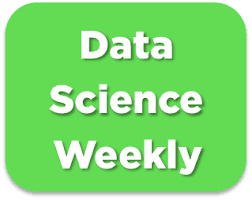

# Challenge : predict conversions 🏆🏆

This is the template that shows the different steps of the challenge. In this notebook, all the training/predictions steps are implemented for a very basic model (logistic regression with only one variable). Please use this template and feel free to change the preprocessing/training steps to get the model with the best f1-score ! May the force be with you 🧨🧨  

**For a detailed description of this project, please refer to *02-Conversion_rate_challenge.ipynb*.**

# 1. Chargement et exploration des données

## Bibliothèques


In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
# setting Jedha color palette as default
pio.templates["jedha"] = go.layout.Template(
    layout_colorway=["#4B9AC7", "#4BE8E0", "#9DD4F3", "#97FBF6", "#2A7FAF", "#23B1AB", "#0E3449", "#015955"]
)
pio.templates.default = "jedha"
from IPython.display import display

## Lecture du fichier labelisé


In [2]:
data = pd.read_csv('data/raw/conversion_data_train.csv')
print('Set with labels (our train+test) :', data.shape)

Set with labels (our train+test) : (284580, 6)


In [3]:
data.head()

,country,age,new_user,source,total_pages_visited,converted
0,China,22,1,Direct,2,0
1,UK,21,1,Ads,3,0
2,Germany,20,0,Seo,14,1
3,US,23,1,Seo,3,0
4,US,28,1,Direct,3,0


## Vue d'ensemble

Nous allons tout d'abord observer la composition du jeu de données

In [4]:
data.describe(include='all')

,country,age,new_user,source,total_pages_visited,converted
count,284580,284580.000000,284580.000000,284580,284580.000000,284580.000000
unique,4,NaN,NaN,3,NaN,NaN
top,US,NaN,NaN,Seo,NaN,NaN
freq,160124,NaN,NaN,139477,NaN,NaN
mean,NaN,30.564203,0.685452,NaN,4.873252,0.032258
std,NaN,8.266789,0.464336,NaN,3.341995,0.176685
min,NaN,17.000000,0.000000,NaN,1.000000,0.000000
25%,NaN,24.000000,0.000000,NaN,2.000000,0.000000
50%,NaN,30.000000,1.000000,NaN,4.000000,0.000000
75%,NaN,36.000000,1.000000,NaN,7.000000,0.000000


Nous observons les points suivants:

- toutes les colonnes sont completes. Il ne sera donc pas necessaire de faire de l'imputation de valeur.
- Seulement 3,2 % des visites aboutissent sur un abonnement. C'est pour cela qu'on prefere utiliser le f1-score comme metrique plutôt que l'accuracy.
- L'âge maximal de 123 ans est aberant.


## Âges aberrants

Nous allons afficher les âges les plus élevés du catalogue afin de voir si s'il est nécessaire de faire un tri sur des valeurs possiblement aberrantes. 


In [5]:
data.sort_values('age', ascending=False).head(10)

,country,age,new_user,source,total_pages_visited,converted
233196,Germany,123,0,Seo,15,1
11331,UK,111,0,Ads,10,1
230590,US,79,1,Direct,1,0
268311,US,77,0,Direct,4,0
175251,US,73,1,Seo,5,0
104541,US,72,1,Direct,4,0
121537,UK,70,0,Ads,5,0
166051,US,70,1,Ads,9,0
113023,China,69,1,Ads,4,0
111431,US,68,1,Direct,5,0


Nous observons deux lignes vraisemblablement aberrantes : 123 ans et 111 ans. À l'exception de ces deux lignes, l'âge le plus élevé est 79 ans, Valeur en dessous de laquelle on observe une forme de continuité dans les âges.
Notons de plus que l'âge de 123 ans n'a jamais été atteint. L'âge de 111 ans est techniquement possible, toutefois nous allons l'écarter en raison de l'écart avec la valeur suivante, qui nous amène à conclure à une valeur aberrante. Nous supprimons donc ces deux lignes.  


In [6]:
data = data.loc[data['age'] < 100, :]
print(data.shape)

(284578, 6)


## Chaque variable seule

Nous allons tout d'abord observer Les données concernant les utilisateurs du site sur chacune des variables. Cela nous permettra de nous donner une idée de sa constitution. 

Nous allons commencer par la répartition géographique. 


### Pays

In [7]:
country_share = data['country'].value_counts(normalize=True).mul(100).reset_index()
fig = px.bar(country_share, x='country', y='proportion')
fig.show()

### Age

In [8]:
fig = px.histogram(data, x='age', histnorm='percent')
fig.show()

Nous observons une population jeune qui démarre à partir de 17 ans. La moyenne est de 30 ans et le 3eme quartile à 36 ans (voir tableau precedent).

### Nouveau visiteur

In [9]:
new_user_share = data['new_user'].value_counts(normalize=True).mul(100).reset_index()
fig = px.bar(new_user_share, x='new_user', y='proportion')
fig.update_xaxes(type='category')
fig.show()

Environ les deux tiers des visites sont faites par de nouveaux visiteurs.

### Source de trafic


In [10]:
source_share = data['source'].value_counts(normalize=True).mul(100).reset_index()
fig = px.bar(source_share, x='source', y='proportion')
fig.show()

Environ la moitié des personnes viennent sur le site depuis un moteur de recherche. La publicité represente 28% des arrivées ; l'acces direct 23%. 

### Nombre de pages visitées


In [11]:
fig = px.histogram(data, x='total_pages_visited', histnorm='percent')
fig.show()

Nous observons que la plupart des visites sont relativement courtes. Le troisième quartile est à 7 pages (voir tableau precedent). 

## Liens entre les variables et la conversion

Nous allons étudier la matrice de corrélation entre les différentes variables afin de repérer d'éventuels liens. 
Nous n'allons traiter que les variables numériques, et donc les variables catégorielles, telles que le pays ou la source, ne seront pas traitées dans cette matrice mais separement. Elle permet d'avoir un premier aperçu. 


In [12]:
corr_matrix = data.corr(numeric_only=True).round(2)
fig = px.imshow(corr_matrix, text_auto=True)
fig.show()

Comme indiqué par l'énoncé, c'est effectivement le nombre de pages visitées qui est la variable la plus fortement corrélée à la conversion, avec un taux de corrélation de 0,53. 


### Conversion par pays

La matrice de corrélation ne permet pas d'étudier le lien éventuel entre le niveau de conversion et les différentes variables catégorielles : nous allons étudier ce lien ici pour la variable « pays ». 

In [13]:
country_conversion = data.groupby('country')['converted'].mean().mul(100).reset_index()
fig = px.bar(country_conversion, x='country', y='converted')
fig.show()

Nous observons que le taux de conversion varie fortement suivant les pays. Le plus haut taux de conversion est celui de l'Allemagne avec 6,2 %, suivi du UK avec 5,2 %, puis les États-Unis avec 3,8 %, et enfin la Chine ne convertit presque pas, avec seulement 0,13 %. Comme nous l'avions vu précédemment, la Chine apporte environ un quart des accès aux sites, mais presque aucun nouvel abonné.
Nous pouvons conclure, à ce stade, que le pays est effectivement une variable significative pour le modèle de prédiction, et le cas de la Chine donne une première piste pour les recommandations à venir. 

### Conversion par source


In [14]:
source_conversion = data.groupby('source')['converted'].mean().mul(100).reset_index()
fig = px.bar(source_conversion, x='source', y='converted')
fig.show()

Nous observons que le taux de conversion n'est que faiblement corrélé à la source : 3,5 % pour la publicité, 3,3 % pour les moteurs de recherche et 2,8 % pour l'accès direct. 


### Conversion selon le statut du visiteur

Nous pouvons soulever un biais méthodologique dans l'approche utilisée pour le relevé des données. 
En effet, les utilisateurs qui visitent le site en étant déjà abonnés eux-mêmes ont une probabilité nulle de s'abonner de nouveau. Leur activité tend donc à biaiser l'analyse essentiellement en attribuant aux utilisateurs ne s'abonnant pas des comportement carateristiques de ceux qui se sont precisement abonnés par le passé. 
En l'état, les données ne permettront pas de supprimer ce biais, mais nous pouvons essayer d'apprécier son ampleur possible en étudiant le taux de conversion chez les visiteurs déjà venus versus celui des visiteurs nouveaux. 



In [15]:
new_user_conversion = data.groupby('new_user')['converted'].mean().mul(100).reset_index()
fig = px.bar(new_user_conversion, x='new_user', y='converted')
fig.update_xaxes(type='category')
fig.show()


Nous observons avec ce diagramme que les visiteurs déjà venus convertissent environ cinq fois plus que les nouveaux visiteurs : 7,2 % contre 1,4 %.

Cette observation nous permet de conclure que, si le biais existe, il n'est probablement pas dominant, car les visiteurs déjà venus ont un taux de conversion plus élevé alors que l'effet d'un abonnement déjà existant devrait avoir tendance à réduire ce taux. Toutefois, le bias n'est pas écarté, ene ffet Le taux de conversion chez les utilisateurs déjà venus peut être plus élevé pour d'autres raisons, telles que, par exemple, l'intérêt qu'il manifeste au sujet. Il se peut donc que ce taux soit plus élevé chez les utilisateurs deja venu, en dépit d'une réduction liée à la visite de personnes déjà abonnées. 
Pour écarter définitivement ce biais, une donnée supplémentaire serait nécessaire, notamment de savoir si le visiteur est déjà abonné ou non. En l'état, nous pouvons simplement conclure que le taux de 7,2 % est possiblement sous-estimé. 


### Nombre de pages visité suivant que la conversion a lieu ou non


La matrice de corrélation nous a permis de comprendre que le nombre de pages visitées était la variable la plus corrélée à la conversion. Nous allons ici examiner cette donnée de plus près en séparant le groupe des visiteurs convertis de celui ne convertissant pas. Nous allons donc générer deux diagrammes, un par groupe.


In [16]:
fig = px.histogram(data.loc[data['converted'] == 0, :], x='total_pages_visited', histnorm='percent', range_x=[0, 30])
fig.show()

Nous pouvons constater ici que les visites non converties sont relativement courtes. La moitié de ces visites s'etend sur 4 pages ou moins. Le maximum est de 20 pages.

In [17]:
fig = px.histogram(data.loc[data['converted'] == 1, :], x='total_pages_visited', histnorm='percent', range_x=[0, 30])
fig.show()

Les visites qui convertissent sont clairement plus longues. La moitié d'entre elles s'étend sur 14 pages au plus au lieu de 4 précédemment. 
Il est intéressant de noter que la zone de recouvrement entre les deux courbes est faible et il s'agit donc de groupes assez clairement distincts. 

# 2. Modèle de référence

## Choix de la variable et de la cible
**From the EDA, we know that the most useful feature is total_pages_visited. Let's create a baseline model by using at first only this feature : in the next cells, we'll make preprocessings and train a simple (univariate) logistic regression.**

In [18]:
features_list = ['total_pages_visited']
numeric_indices = [0]
categorical_indices = []
target_variable = 'converted'

In [19]:
X = data.loc[:, features_list]
Y = data.loc[:, target_variable]

print('Explanatory variables : ', X.columns)
print()

Explanatory variables :  Index(['total_pages_visited'], dtype='object')



## Découpage en train et test

Les données sont séparées en deux catégories. Nous en gardons 90 % pour entraîner le modèle et 10 % pour le tester. Contrairement à ce qui était proposé par l'énoncé, j'ai choisi de faire un découpage stratifié pour permettre d'avoir la même part de visites converties dans le train et dans le test. 

In [20]:
print("Dividing into train and test sets...")
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.1, random_state=0, stratify=Y)
print("...Done.")
print()
print('Conversion rate in train set : ', Y_train.mean())
print('Conversion rate in test set : ', Y_test.mean())

Dividing into train and test sets...
...Done.

Conversion rate in train set :  0.03225050757457442
Conversion rate in test set :  0.03225806451612903


Comme prévu, le taux de conversion est le même dans chacun des deux ensembles. 

## Training pipeline

### Standardisation

In [21]:
# Put here all the preprocessings
print("Encoding categorical features and standardizing numerical features...")

featureencoder = StandardScaler()
X_train = featureencoder.fit_transform(X_train)
print("...Done")
print(X_train[0:5,:])

Encoding categorical features and standardizing numerical features...
...Done
[[-0.26099836]
 [ 0.03829244]
 [-0.56028917]
 [-1.15887077]
 [ 0.33758325]]


In [22]:
print('Mean : ', featureencoder.mean_)
print('Standard deviation : ', featureencoder.scale_)

Mean :  [4.87205607]
Standard deviation :  [3.34123196]


Les valeurs sont maintenant exprimées en écarts-types par rapport à la moyenne du train (z-score)(ici la moyenne est de 4,87 pages visitées). Une valeur négative correspond à une visite plus courte que la moyenne.

### Régression logistique

On entraîne le modèle sur l'ensemble train à l'aide d'une régression logistique. 

In [23]:
# Train model
print("Train model...")
classifier = LogisticRegression() # 
classifier.fit(X_train, Y_train)
print("...Done.")

Train model...
...Done.


In [24]:
print('Coefficient : ', classifier.coef_)
print('Intercept : ', classifier.intercept_)

Coefficient :  [[2.5326788]]
Intercept :  [-6.57314238]


L'intercept et le coefficient définissent ensemble une droite. Cette droite permet l'attribution d'un score à chaque visite selon nombre standardisé de pages visitées z.

$$\text{score} = -6{,}57 + 2{,}53 \times z$$

C'est cette droite qui permet de découper les visites en deux groupes. Là où le score est négatif, le modèle prédit une absence de conversion. Là où il est positif, il prédit une conversion. La bascule se fait quand le score vaut 0, soit à 13,5 pages : le modèle prédit donc une conversion à partir de 14 pages visitées.

Le modèle a choisi ces deux paramètres pour que les probabilités de conversion qu'il en déduit collent le mieux possible aux issues observées sur le train.


In [25]:
# Predictions on training set
print("Predictions on training set...")
Y_train_pred = classifier.predict(X_train)
print("...Done.")
print(Y_train_pred)
print()

Predictions on training set...
...Done.
[0 0 0 ... 0 0 0]



Le modele a ici été utilisé pour fournir une prédiction sur le train. Le resultat sera analysé plus loin.

## Test pipeline

Nous allons maintenant evaluer ce premier modele sur les données de test (labelisées). Pour cela nous devons d'abord appliquer à l'ensemble test les meme transformations que celles du train.

In [26]:
# Use X_test, and the same preprocessings as in training pipeline, 
# but call "transform()" instead of "fit_transform" methods (see example below)

print("Encoding categorical features and standardizing numerical features...")

X_test = featureencoder.transform(X_test)
print("...Done")
print(X_test[0:5,:])

Encoding categorical features and standardizing numerical features...
...Done
[[ 2.73190968]
 [ 0.03829244]
 [-0.26099836]
 [ 0.93616485]
 [ 0.93616485]]


Le modelele est appliqué ici

In [27]:
# Predictions on test set
print("Predictions on test set...")
Y_test_pred = classifier.predict(X_test)
print("...Done.")
print(Y_test_pred)
print()

Predictions on test set...
...Done.
[1 0 0 ... 0 0 0]



## Performance assessment

Le modele est maintenant évalué sur le train et sur le test sur la base du f1-score comme metrique, tel que précedement discuté.

In [28]:
# WARNING : Use the same score as the one that will be used by Kaggle !
# Here, the f1-score will be used to assess the performances on the leaderboard
print("f1-score on train set : ", f1_score(Y_train, Y_train_pred))
print("f1-score on test set : ", f1_score(Y_test, Y_test_pred))

f1-score on train set :  0.6950136373172949
f1-score on test set :  0.6961394769613948


Le f1-score est presque identique sur le train et sur le test (0.695 et 0.696). pas d'overfit constaté.

In [29]:
# You can also check more performance metrics to better understand what your model is doing
print("Confusion matrix on train set : ")
print(confusion_matrix(Y_train, Y_train_pred))
print()
print("Confusion matrix on test set : ")
print(confusion_matrix(Y_test, Y_test_pred))
print()

Confusion matrix on train set : 
[[246790   1070]
 [  3291   4969]]

Confusion matrix on test set : 
[[27411   129]
 [  359   559]]



Sur le test, le modele a fait 688 prediction dont 559 se sont averées exactes (true positive). La precision est donc de 81%.
du coté du recall toutefois, il ne trouve que 559 visites converties (TP) sur 918 reelles (TP + FN), soit 61%. Cela signifie qu'il en rate pres de 4/10. 

Le f1-score calculé de 0.696 est le f1-score de base qui servira de reference devant etre battu par les modeles suivants.

**Our baseline model reaches a f1-score of almost 70%. Now, feel free to refine your model and try to beat this score ! 🚀🚀**

# 3. Prétraitement complet et modèle sur toutes les variables

## Choix des variables

Nous allons maintenant travailler sur le modèle avec les cinq variables. Certaines de ces variables sont numériques et d'autres catégorielles ; elles seront donc traitées séparément.


In [30]:
features_list = ['country', 'age', 'new_user', 'source', 'total_pages_visited']
numeric_features = ['age', 'total_pages_visited']
categorical_features = ['country', 'new_user', 'source']

X = data.loc[:, features_list]
Y = data.loc[:, target_variable]

X.head()

,country,age,new_user,source,total_pages_visited
0,China,22,1,Direct,2
1,UK,21,1,Ads,3
2,Germany,20,0,Seo,14
3,US,23,1,Seo,3
4,US,28,1,Direct,3


## Découpage en train et test

Pour ce découpage, nous allons appliquer le même paramétrage que précédemment. 


In [31]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.1, random_state=0, stratify=Y)
print(X_train.shape)
print(X_test.shape)

(256120, 5)
(28458, 5)


## Prétraitement

Comme précisé précédemment, nous allons traiter séparément les variables numériques des variables catégorielles. 
Les variables numériques sont standardisées, comme pour le modèle de référence.
Les variables catégorielles sont transformées À l'aide d'un one-hot encoder qui dedie une colonne à chacune de leurs valeurs et associe un 1 à la valeur en question, 0 au reste.
Afin d'éviter la colinéarité des nouvelles colonnes, il convient d'en supprimer une par variable categorielle et nous optons pour la stratégie drop = first. 


In [32]:
numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(drop='first')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print(preprocessor.get_feature_names_out())
print(X_train[0:5, :])

['num__age' 'num__total_pages_visited' 'cat__country_Germany'
 'cat__country_UK' 'cat__country_US' 'cat__new_user_1'
 'cat__source_Direct' 'cat__source_Seo']
[[-1.51987065 -0.26099836  0.          0.          1.          0.
   0.          1.        ]
 [ 2.2307148   0.03829244  0.          0.          0.          0.
   0.          1.        ]
 [ 1.86775492 -0.56028917  0.          0.          0.          1.
   0.          1.        ]
 [-1.51987065 -1.15887077  0.          0.          1.          0.
   0.          0.        ]
 [-1.03592414  0.33758325  0.          0.          1.          1.
   0.          0.        ]]


Nous obtenons un total de 8 colonnes.


## Entraînement et évaluation

Nous allons ici entraîner le modèle avec une régression logistique sur les 8 colonnes et l'évaluer de la même façon que le modèle référent.

In [33]:
print("Train model...")
classifier = LogisticRegression()
classifier.fit(X_train, Y_train)
print("...Done.")

Train model...
...Done.


In [34]:
Y_train_pred = classifier.predict(X_train)
Y_test_pred = classifier.predict(X_test)

print("f1-score on train set : ", f1_score(Y_train, Y_train_pred))
print("f1-score on test set : ", f1_score(Y_test, Y_test_pred))

f1-score on train set :  0.7627925692441822
f1-score on test set :  0.7711711711711712


In [35]:
print("Confusion matrix on train set : ")
print(confusion_matrix(Y_train, Y_train_pred))
print()
print("Confusion matrix on test set : ")
print(confusion_matrix(Y_test, Y_test_pred))

Confusion matrix on train set : 
[[246896    964]
 [  2573   5687]]

Confusion matrix on test set : 
[[27435   105]
 [  276   642]]


Le f1-score est passé de 0,696 à 0,771 sur le test, c'est assez proche du score du train (0,763). Le modèle ne sur-apprend toujours pas.

Sur le test, le modèle prédit 747 conversions, dont 642 sont réelles : la précision est de 86 %, contre 81 % pour le modèle de référence. Il retrouve 642 des 918 visites réellement converties : le recall est de 70 %, contre 61 %. Les 4 variables ajoutées apportent donc une information que le nombre de pages visitées ne contenait pas. Le recall reste le point faible : le modèle rate encore trois conversions sur dix.


# 4. Amélioration du f1-score

## Ajustement du seuil de décision

Le modèle effectue une prédiction en fonction d'un seuil qui est fixé par défaut à 50 %. Nous allons tester d'autres seuils afin de déterminer si un des seuils permet de donner de meilleurs résultats.
Nous allons calculer le F1 score sur le train pour tous les seuils allant de 0,1 à 0,9 avec un pas de 0,05. 


In [36]:
Y_train_proba = classifier.predict_proba(X_train)[:, 1]

thresholds = np.arange(0.1, 0.95, 0.05).round(2)
scores = [f1_score(Y_train, Y_train_proba >= t) for t in thresholds]

threshold_scores = pd.DataFrame({'threshold': thresholds, 'f1_train': scores})
threshold_scores

,threshold,f1_train
0,0.10,0.665902
1,0.15,0.711644
2,0.20,0.739614
3,0.25,0.752850
4,0.30,0.763931
5,0.35,0.770045
6,0.40,0.770890
7,0.45,0.769120
8,0.50,0.762793
9,0.55,0.754447


Le f1-score atteint une zone relativement plate entre 0.3 et 0.55 avec un maximum atteint à 0.4. Il atteint alors la valeur de 0.7709.

Nous allons donc conserver cette valeur de 0,4 comme étant le seuil optimal pour ce modèle. 

In [37]:
threshold = 0.4

Y_test_proba = classifier.predict_proba(X_test)[:, 1]
Y_train_pred = (Y_train_proba >= threshold).astype(int)
Y_test_pred = (Y_test_proba >= threshold).astype(int)

print("f1-score on train set : ", f1_score(Y_train, Y_train_pred))
print("f1-score on test set : ", f1_score(Y_test, Y_test_pred))
print()
print("Confusion matrix on test set : ")
print(confusion_matrix(Y_test, Y_test_pred))

f1-score on train set :  0.7708901719434046
f1-score on test set :  0.7667804323094426

Confusion matrix on test set : 
[[27374   166]
 [  244   674]]


Avec ce seuil de 0,4, on obtient davantage de conversions. 674 conversions sont correctement prédites sur 918, alors que cette valeur était de seulement 642 avec un seuil de 0,5. 

## Comparaison avec un modèle non linéaire

Nous allons également tester un modèle non linéaire, ici une forêt aléatoire.
Pour cela, nous avons besoin essentiellement de trois hyperparamètres:
- max_depth: Profondeur maximale: Il s'agit du nombre maximal de questions successive portant sur une visite avant qu'elle ateigne une feuille.
- min_samples_leaf: Il s'agit de la taille minimale d'une feuille, c'est-à-dire le nombre minimal de visites qu'un groupe en bout de branche doit contenir. 
- n_estimators: C'est le nombre d'arbres constituant la forêt. Le vote est d'autant plus stable que ce nombre est élevé, mais le calcul est également plus long. 

Les paramètres choisis dans le code ci-dessous sont des paramètres usuels. Il y aura trois valeurs pour max_depth, 2 pour min_samples_leaf et 2 pour n_estimators, soit 3 x 2 x 2 = 12 combinaisons. Avec un cv de 3, cela donnes 36 forets. c'est une valeur raisonable pour le calcul.

In [38]:
params = {
    'max_depth': [6, 8, 10],
    'min_samples_leaf': [1, 5],
    'n_estimators': [50, 100]
}
gridsearch = GridSearchCV(RandomForestClassifier(random_state=0), param_grid=params, cv=3, scoring='f1')
gridsearch.fit(X_train, Y_train)

print("Best hyperparameters : ", gridsearch.best_params_)
print("Best validation f1-score : ", gridsearch.best_score_)

Best hyperparameters :  {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 50}
Best validation f1-score :  0.7574668192035117


La meilleure combinaison est une forêt de 50 arbres, de profondeur 10, avec au moins 5 visites par feuille. Son f1-score moyen en validation croisée est de 0,757.



In [39]:
print("f1-score on train set : ", f1_score(Y_train, gridsearch.predict(X_train)))
print("f1-score on test set : ", f1_score(Y_test, gridsearch.predict(X_test)))
print()
print("Confusion matrix on test set : ")
print(confusion_matrix(Y_test, gridsearch.predict(X_test)))

f1-score on train set :  0.773946874161524
f1-score on test set :  0.748792270531401

Confusion matrix on test set : 
[[27422   118]
 [  298   620]]


Le f1-score obtenu par forret aleatoire est de 0,749 sur le test. Il etait de 0,767 pour la régression logistique. Le sur-apprentissage est léger, elle obtient 0,774 sur le train.

Le modèle des arbres aléatoires performe moins bien que la régression logistique. Nous conservons donc cette dernière. 


### Train best classifier on all data and use it to make predictions on X_without_labels
**Before making predictions on the file conversion_data_test.csv, let's train our model on ALL the data that was in conversion_data_train.csv. Sometimes, this allows to make tiny improvements in the score because we're using more examples to train the model.**

# 5. Prédictions sur le fichier sans étiquettes
## Réentraînement sur toutes les données étiquetées

Nous avons retenu la régression logistique avec les cinq variables et un seuil de 0,4. Toutefois, avant d'appliquer ce modèle sur l'ensemble non labellisé, il convient de le préprocesser et de le réentraîner de nouveau sur l'ensemble des données labellisées (donc train + test). Ce modèle final ne pourra évidemment plus être évalué, et le score à retenir sera donc celui obtenu précédemment.  

In [40]:
X = data.loc[:, features_list]
Y = data.loc[:, target_variable]

X = preprocessor.fit_transform(X)
classifier.fit(X, Y)
print(X.shape)

(284578, 8)


## Lecture du fichier sans étiquettes


In [41]:
data_without_labels = pd.read_csv('data/raw/conversion_data_test.csv')
print('Prediction set (without labels) :', data_without_labels.shape)

data_without_labels.describe(include='all')

Prediction set (without labels) : (31620, 5)


,country,age,new_user,source,total_pages_visited
count,31620,31620.000000,31620.000000,31620,31620.000000
unique,4,NaN,NaN,3,NaN
top,US,NaN,NaN,Seo,NaN
freq,17968,NaN,NaN,15563,NaN
mean,NaN,30.620746,0.685579,NaN,4.870398
std,NaN,8.316736,0.464292,NaN,3.333128
min,NaN,17.000000,0.000000,NaN,1.000000
25%,NaN,24.000000,0.000000,NaN,2.000000
50%,NaN,30.000000,1.000000,NaN,4.000000
75%,NaN,36.000000,1.000000,NaN,7.000000


Il y a cette fois-ci 31 620 visites. La colonne cible, comme prévu, est absente et nous constatons qu'il n'y a pas de données manquantes. 

## Prétraitement et prédictions

Nous appliquons le modèle tel que defini.

In [42]:
X_without_labels = data_without_labels.loc[:, features_list]
X_without_labels = preprocessor.transform(X_without_labels)
print(X_without_labels[0:5, :])

[[-0.31022704  3.32945122  0.          1.          0.          0.
   0.          1.        ]
 [-1.03630176  0.03794265  0.          1.          0.          1.
   1.          0.        ]
 [ 0.17382278 -1.15896955  0.          0.          0.          1.
   0.          1.        ]
 [ 0.17382278  0.3371707   0.          0.          1.          1.
   0.          0.        ]
 [-0.6732644  -0.56051345  0.          0.          0.          0.
   0.          1.        ]]


In [43]:
Y_without_labels_proba = classifier.predict_proba(X_without_labels)[:, 1]

Y_predictions = pd.DataFrame({'converted': (Y_without_labels_proba >= threshold).astype(int)})
Y_predictions.to_csv('data/processed/conversion_data_test_predictions_JULIEN-model1.csv', index=False)

print(Y_predictions['converted'].value_counts())

converted
0    30700
1      920
Name: count, dtype: int64


Le modèle effectue ici 920 prédictions sur un total de 31 620 visites, soit 2,9 % sur le fichier labellisé. Le taux était de 3,2 %, ce qui est relativement proche. 

# 6. Lecture du modèle et recommandations

## Influence de chaque variable

Nous allons ici étudier la valeur de chaque coefficient du modèle. Ces valeurs représentent l'effet de chaque vairable sur la prédiction, toutes choses étant égales par ailleurs. Un coefficient positif signifie que la variable favorise la conversion ; à l'inverse, un coefficient négatif signifie que la variable defavorise la conversion. Une valeur proche de zéro signifie qu'il n'y a peu ou pas d'effets. 

### Analyzing the coefficients and interpreting the result
**In this template, we just trained a model with only one feature (total_pages_visited), so there's no analysis to be done about the feature importance 🤔**

**Once you've included more features in your model, please take some time to analyze the model's parameters and try to find some lever for action to improve the newsletter's conversion rate 😎😎**

In [44]:
coefs = pd.DataFrame({
    'feature': preprocessor.get_feature_names_out(),
    'coefficient': classifier.coef_[0]
}).sort_values('coefficient')

fig = px.bar(coefs, x='coefficient', y='feature', orientation='h')
fig.show()

print('Intercept : ', classifier.intercept_)
coefs

Intercept :  [-8.64863212]


,feature,coefficient
5,cat__new_user_1,-1.707033
0,num__age,-0.611391
6,cat__source_Direct,-0.208333
7,cat__source_Seo,-0.021028
1,num__total_pages_visited,2.526875
4,cat__country_US,2.993013
3,cat__country_UK,3.327159
2,cat__country_Germany,3.552933


Comme prévu lors de l'établissement de la matrice de corrélation, les effets les plus forts sont ceux attribués aux pays, et plus particulièrement l'Allemagne. L'effet de la Chine a été exclu par construction lorsque nous avons suivi la stratégie drop = first. Par conséquent, sa valeur est arbitrairement nulle et l'effet des autres pays est mesuré par rapport à cette valeur. Les trois pays mentionnés ont donc un effet nettement plus significatif que celui de la Chine sur la conversion. 


## Recommandations

Plusieurs leviers d'action ressortent à la suite de cette analyse. 

Le levier le plus important est clairement la Chine. Le démarquage avec les autres pays est suffisamment élevé pour nécessiter une investigation approfondie. Les raisons de cet écart sont à ce stade inconnues. S'agit-il d'un problème de langue, d'accessibilité ou autre ? 
Une résolution de cette problématique pourrait avoir un effet significatif sur le taux de conversion. 


L'effet du nombre de pages visitées est plus délicat, il est en effet difficile de connaître la relation causale avec l'abonnement. S'agit-il d'une simple corrélation, par exemple, les utilisateurs intéressés naviguent au travers de plus de pages et ont aussi plus de probabilité de s'abonner ? Auquel cas, l'exploitation de ce levier sera difficile. Ou existe-t-il un paramètre causal sur lequel nous pourrions agir pour exploiter ce levier ? 
À ce stade, La recommandation pour exploiter ce levier sera de proposer l'abonnement au bon moment de la visite. C'est-à-dire suffisament loin pour que l'utilisateur se soit déjà construit une idée du site et un intérêt possible pour celui-ci, mais aussi suffisamment tôt pour que l'utilisateur soit toujours present. Nous pouvons proposer d'introduire une suggestion d'abonnement à partir 7 à 8 pages, ce qui semble etre un bon equilibre et qui est juste avant que les visites basculent (environ 10 pages).
L'introduction d'une variable supplementaire telle que la duree de la visite ou le temps passé sur chaque page pourait etre pertinent pour ameliorer ce levier et comprendre les causes qui le gouvernent.

Un autre levier d'agir sur les visiteurs déjà venus. En effet, ils convertissent cinq fois plus que les nouveaux. En lien avec le levier précédent, nous pouvons supposer qu'ils ont déjà acquis une certaine connaissance du site et donc un intérêt probable. Un levier d'action possible est donc d'agir au niveau d'une publicité ciblée basée sur les cookies. De telles publicités permettent de faire un rappel. Une proposition d'abonnement qui interviendrait plus tôt dans la deuxième visite, dès les premières pages, peut également être un autre moyen d'exploiter ce levier. 

La source de trafic n'a visiblement que peu d'effet. Ce point-là n'est toutefois pas contradictoire avec le point précédent, à condition que les publicités soient cette fois-ci ciblées. 
Enfin, l'âge ne semble intervenir que légèrement. 

Nous rappelons la limite de cette étude, qui est que, lors d'une visite, nous n'avons pas la donnée pour savoir si une personne est déjà abonnée ou non. C'est techniquement quelque chose qui peut se résoudre au moins en partie à l'aide de cookies sous reserve d'acceptation de l'utilisateur (RGPD). 



